# 1. Simulated light curves

In [1]:
import sys
sys.path.insert(0, "..")
import json
import numpy as np
import matplotlib.pyplot as plt
from mldtw.simulate import make_dataset, magnification, CLASSES, T

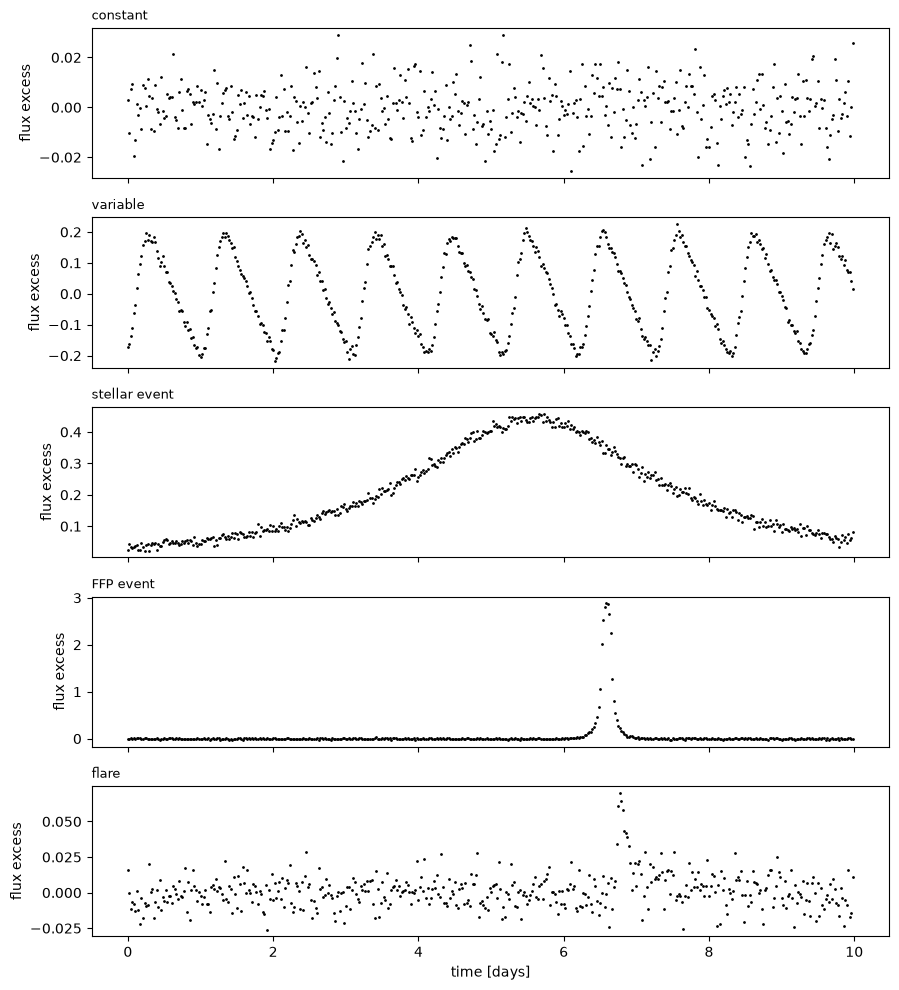

In [2]:
X, y, params = make_dataset(1, seed=42)

fig, axes = plt.subplots(5, 1, figsize=(9, 10), sharex=True)
for k, ax in enumerate(axes):
    ax.plot(T, X[k], "k.", ms=2)
    ax.set_title(CLASSES[k], loc="left", fontsize=9)
    ax.set_ylabel("flux excess")
axes[-1].set_xlabel("time [days]")
plt.tight_layout()
plt.savefig("../figures/examples.png", dpi=150)

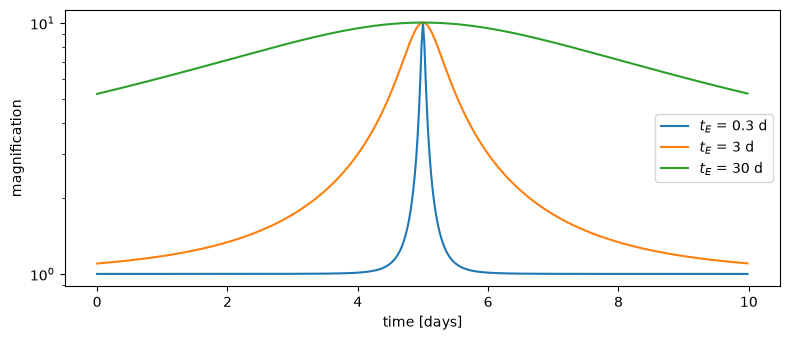

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for tE in [0.3, 3, 30]:
    u = np.sqrt(0.1**2 + ((T - 5) / tE) ** 2)
    ax.plot(T, magnification(u), label=f"$t_E$ = {tE} d")
ax.set_yscale("log")
ax.set_xlabel("time [days]")
ax.set_ylabel("magnification")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/tE.png", dpi=150)

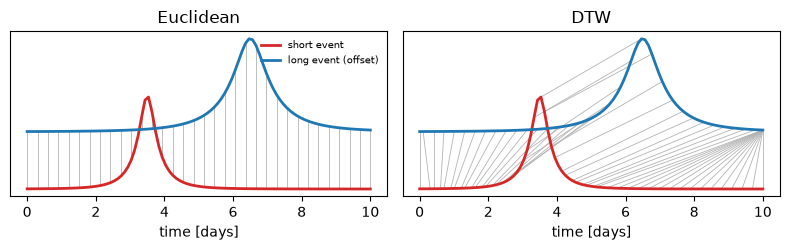

In [4]:
from tslearn.metrics import dtw_path

t = np.linspace(0, 10, 100)
x0 = magnification(np.sqrt(0.3**2 + ((t - 3.5) / 0.8) ** 2)) - 1
x1 = magnification(np.sqrt(0.3**2 + ((t - 6.5) / 1.6) ** 2)) - 1
path, _ = dtw_path(x0, x1)
x1 = x1 + 1.5

fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
for ax, pairs, title in zip(axes, [[(i, i) for i in range(len(t))], path], ["Euclidean", "DTW"]):
    for i, j in pairs[::3]:
        ax.plot([t[i], t[j]], [x0[i], x1[j]], "-", color="0.7", lw=0.6)
    ax.plot(t, x0, "C3", lw=2, label="short event")
    ax.plot(t, x1, "C0", lw=2, label="long event (offset)")
    ax.set_title(title)
    ax.set_xlabel("time [days]")
    ax.set_yticks([])
axes[0].legend(fontsize=7, frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig("../figures/dtw_matching.png", dpi=200)
plt.savefig("../figures/dtw_matching.pdf")